In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv(r"C:\Users\kashv\Desktop\Delhi_UHI_Project\Data\Processed\cleaned_dataset.csv")
df.head()

,Latitude,Longitude,AirTemp,DistanceToWater,Elevation,Humidity,LST,LULC,MNDWI,NDBI,NDVI,Population,Slope,WindSpeed,LULC_Name
0,28.632720,77.204349,32.490555,1065.082156,223,28.763419,41.820506,6,-0.103358,-0.061668,0.161954,190.287857,3.489779,1.422401,Built Area
1,28.614477,77.114090,32.618237,4417.420062,219,28.276358,46.014417,6,-0.089072,-0.004090,0.071271,318.664734,1.854334,1.422094,Built Area
2,28.783908,77.106962,32.277801,56.568542,211,29.923939,44.336169,0,-0.086957,-0.014011,0.089721,0.000000,1.406886,1.355455,Water
3,28.660692,77.147372,32.479869,1059.056184,216,29.162266,45.623053,6,-0.079266,-0.051205,0.125391,268.919067,2.307262,1.391453,Built Area
4,28.814437,76.991782,32.366906,1223.764683,226,29.204621,50.153639,7,-0.151679,0.025338,0.100419,0.000000,4.263645,1.359317,Bare Ground


In [3]:
df = df.drop(columns = ["Latitude","Longitude","LULC_Name"], axis=1)

In [4]:
df.sample(10)

,AirTemp,DistanceToWater,Elevation,Humidity,LST,LULC,MNDWI,NDBI,NDVI,Population,Slope,WindSpeed
4429,32.490555,2641.211843,213,28.763419,44.271226,6,-0.100524,-0.066225,0.164180,24.249008,2.780288,1.422401
1470,32.157099,1520.000000,212,30.554157,41.357364,4,-0.115991,-0.006582,0.108644,0.000000,1.854334,1.348895
923,32.509743,1787.512238,226,28.624378,47.602087,6,-0.113291,-0.025273,0.144128,455.787262,2.808367,1.424831
9029,32.327412,240.000000,214,29.849901,41.003599,6,-0.079532,-0.072297,0.153840,10.117785,1.854334,1.385324
7150,32.641314,1941.957775,282,27.603264,46.549337,6,-0.187575,-0.036581,0.210050,12.624177,5.081887,1.450929
8158,32.366906,544.058820,214,29.204621,45.535894,1,-0.157997,-0.067184,0.223180,0.000000,3.671319,1.359317
3121,32.594268,1429.405471,214,28.426848,51.351655,4,-0.220091,0.047974,0.144809,0.000000,2.974116,1.390905
9811,32.277801,1111.395519,209,29.923939,46.638205,7,-0.123106,0.005126,0.088323,0.000000,1.854334,1.355455
7077,32.410402,622.253967,205,29.284862,47.814004,6,-0.148442,-0.034106,0.172674,0.000000,1.405536,1.405447
2277,32.490555,3733.738073,222,28.763419,44.290026,6,-0.148736,-0.017193,0.137287,105.417160,0.000000,1.422401


In [5]:
X = df.drop("LST", axis=1)
y = df["LST"]

In [6]:
# Train test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=43
)

In [7]:
# Standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [8]:
lr = LinearRegression()
lr.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [9]:
y_pred_train = lr.predict(X_train)
y_pred_test = lr.predict(X_test)

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

print(f"root_mean_squared_error of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"root_mean_squared_error of testing data = {root_mean_squared_error(y_test, y_pred_test)}")

r2_score of training data = 0.7435054296055481
r2_score of testing data = 0.7378327234893977
root_mean_squared_error of training data = 1.7229034978442974
root_mean_squared_error of testing data = 1.7182866419321128


# Visualization

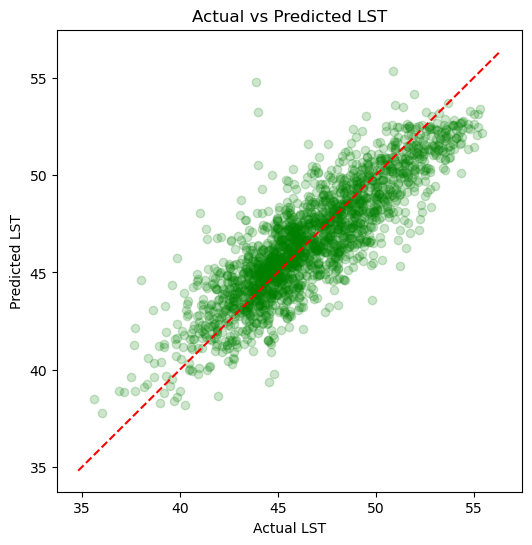

In [10]:
# Actual vs Predictedplt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_test,c="green", alpha=0.2)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel("Actual LST")
plt.ylabel("Predicted LST")
plt.title("Actual vs Predicted LST")
plt.show()

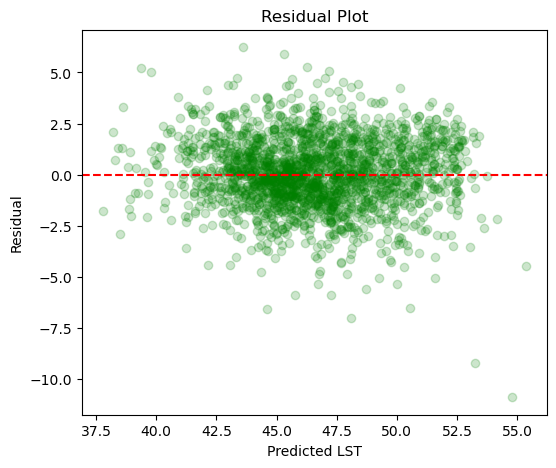

In [12]:
residuals = y_test - y_pred_test

plt.figure(figsize=(6,5))
plt.scatter(y_pred_test, residuals,c="green", alpha=0.2)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted LST")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()